`[1]`

# Disponibilidade de imagens ASTER por semestre — 2000–2008 × 2009–2020

Lê `contagem_imagens_aster_semestre.csv` (gerado por `contar_imagens_semestre.py`)
e faz os gráficos por semestre, separados nos dois grandes períodos do projeto:

- **2000–2008** — cenas com SWIR (até 2008-S2);
- **2009–2020** — só VNIR + TIR (o SWIR é estimado).

Contagens usadas (mesmos filtros de `build_mosaicos_semestrais.py`):

| nome no gráfico | coluna / conta |
|---|---|
| disponíveis (diurnas) | `diurnas` — com SWIR (`com_swir`) e sem SWIR |
| noturnas | `noturnas` (só TIR, não entram) |
| fora por nuvem (CC ≥ 77) | `diurnas − cc_lt_max` |
| fora pela blacklist | `cc_lt_max − apos_blacklist` (`lista_imagens_Notaceites.txt`) |
| **finais** (compõem o mosaico) | `apos_blacklist` |
| zero nuvem | `zero_cloud` (finais que estão em `list_zero_cloud.txt`) |
| finais com máscara de nuvem | `apos_blacklist − zero_cloud` |

As figuras são salvas a 350 dpi em `figuras_contagem/`.

In [32]:
# [2]
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PASTA = Path.cwd()
CSV = PASTA / 'contagem_imagens_aster_semestre.csv'
FIGS = PASTA / 'figuras_contagem'
FIGS.mkdir(exist_ok=True)
DPI_FIG = 350
FS = 16          # tamanho base das fontes de todos os gráficos
PERIODOS = {'2000–2008': (2000, 2008), '2009–2020': (2009, 2020)}

COR = {'com_swir': '#1f77b4', 'sem_swir': '#9ecae1', 'noturnas': '#d9d9d9',
       'nuvem': '#fdd0a2', 'blacklist': '#e6550d', 'mascara': '#74c476', 'zero': '#006d2c'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})

def salvar(fig, celula, nome):
    arq = FIGS / f'c{celula}_{nome}.png'
    fig.savefig(arq, dpi=DPI_FIG, bbox_inches='tight')
    print(f'figura → {arq.name}')

df = pd.read_csv(CSV)
df['rotulo'] = df.ano.astype(str) + '-S' + df.semestre.astype(str)
df['periodo'] = np.where(df.ano <= 2008, '2000–2008', '2009–2020')
df['sem_swir'] = df.diurnas - df.com_swir
df['fora_nuvem'] = df.diurnas - df.cc_lt_max
df['fora_blacklist'] = df.cc_lt_max - df.apos_blacklist
df['finais'] = df.apos_blacklist
df['finais_mascara'] = df.apos_blacklist - df.zero_cloud
df[['rotulo', 'periodo', 'total', 'diurnas', 'com_swir', 'noturnas', 'fora_nuvem',
    'fora_blacklist', 'finais', 'zero_cloud']]

,rotulo,periodo,total,diurnas,com_swir,noturnas,fora_nuvem,fora_blacklist,finais,zero_cloud
0,2000-S1,2000–2008,24,13,13,11,0,7,6,2
1,2000-S2,2000–2008,207,207,207,0,46,67,94,10
2,2001-S1,2000–2008,289,289,289,0,47,148,94,9
3,2001-S2,2000–2008,165,165,165,0,30,90,45,7
4,2002-S1,2000–2008,39,39,39,0,13,2,24,0
5,2002-S2,2000–2008,46,46,46,0,0,27,19,4
6,2003-S1,2000–2008,7,7,7,0,0,1,6,4
7,2003-S2,2000–2008,45,45,45,0,4,32,9,1
8,2004-S1,2000–2008,25,25,25,0,2,17,6,0
9,2004-S2,2000–2008,4,4,4,0,0,3,1,0


`[3]`

## Gráfico 1 — disponibilidade por semestre

Barras empilhadas: cenas diurnas com SWIR, diurnas sem SWIR e noturnas. Um
painel por período, mesmo eixo vertical. O número em cima da barra é o total
de cenas diurnas (as que podem entrar no mosaico).

figura → c4_disponibilidade_semestre.png


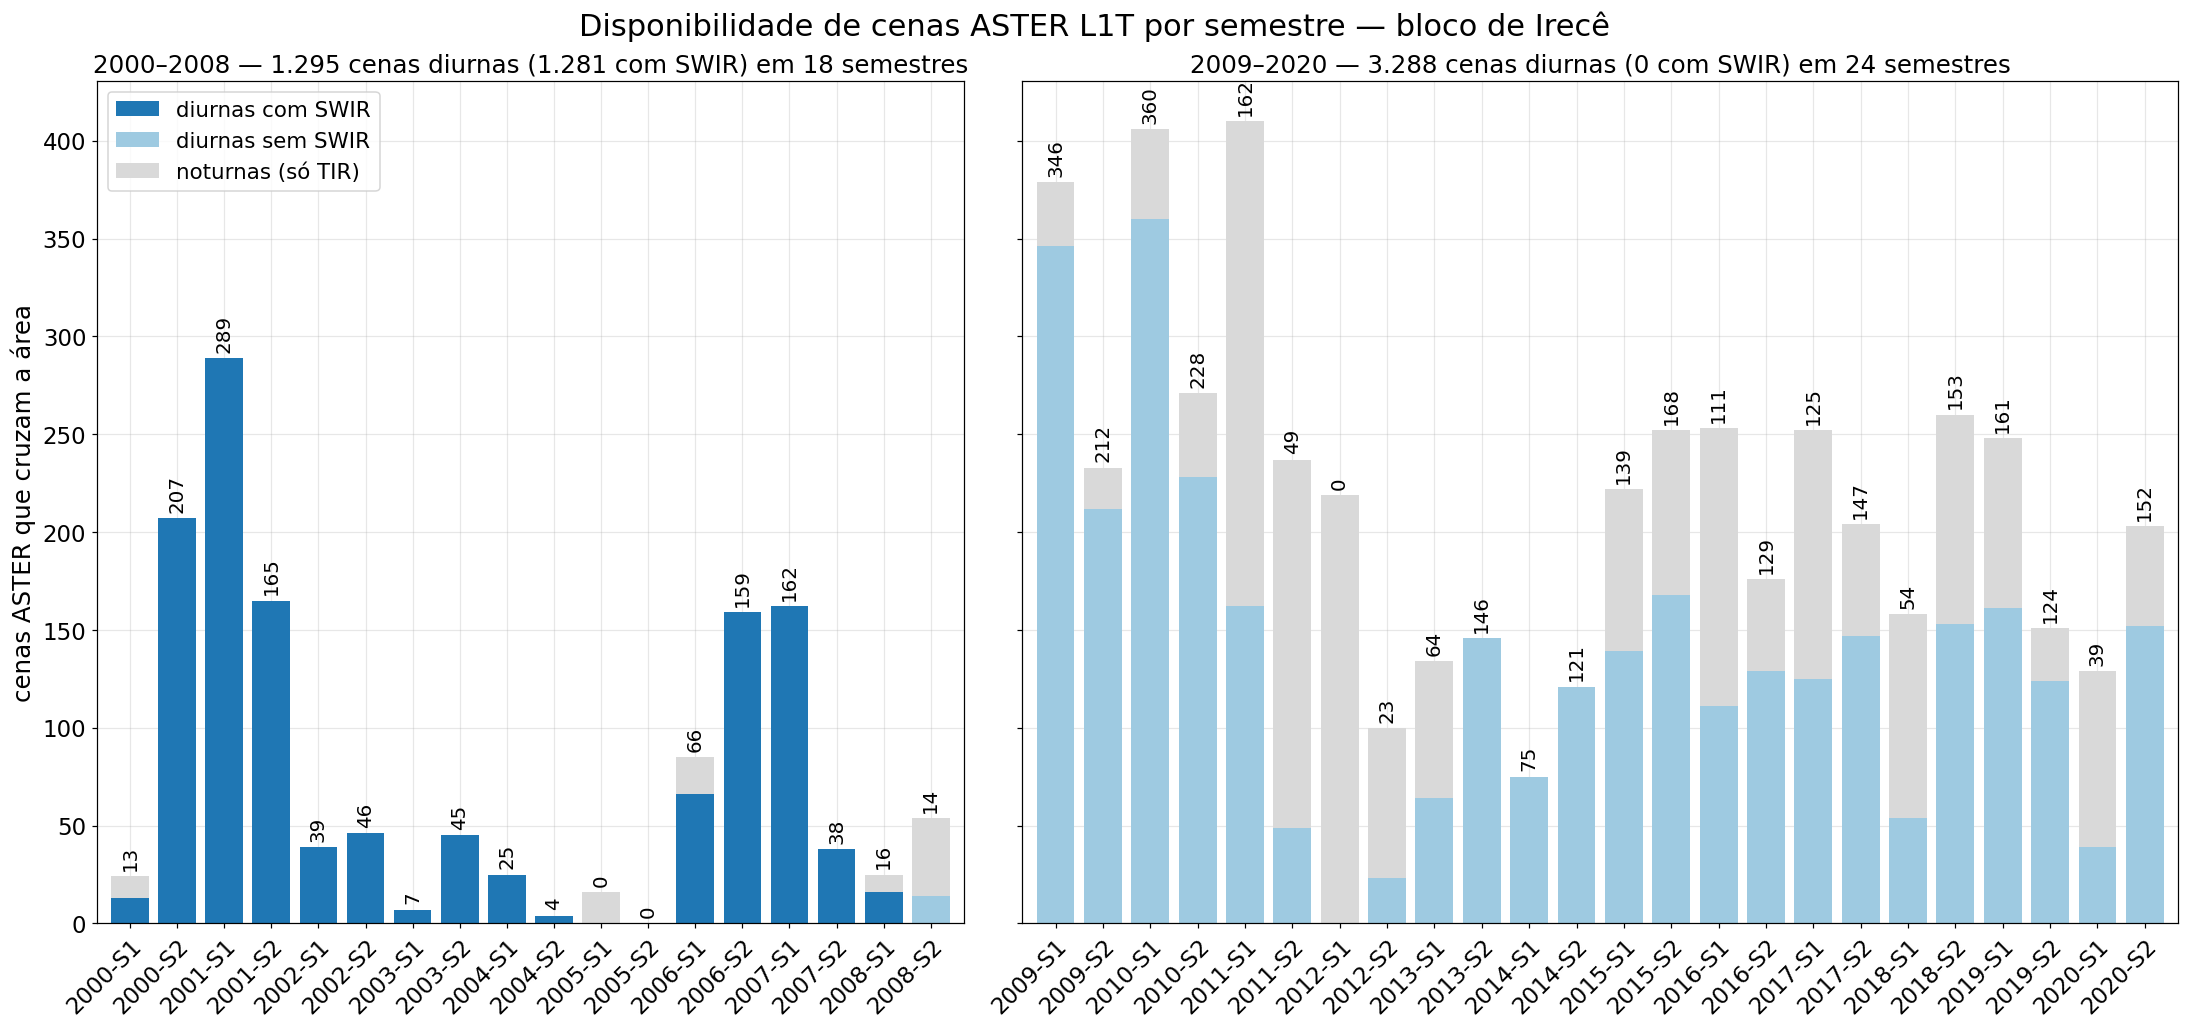

In [33]:
# [4]
fig, axs = plt.subplots(1, 2, figsize=(20, 9.5), sharey=True,
                        gridspec_kw={'width_ratios': [18, 24]})
for ax, (nome, (a0, a1)) in zip(axs, PERIODOS.items()):
    d = df[(df.ano >= a0) & (df.ano <= a1)].reset_index(drop=True)
    x = np.arange(len(d))
    ax.bar(x, d.com_swir, color=COR['com_swir'], label='diurnas com SWIR')
    ax.bar(x, d.sem_swir, bottom=d.com_swir, color=COR['sem_swir'], label='diurnas sem SWIR')
    ax.bar(x, d.noturnas, bottom=d.diurnas, color=COR['noturnas'], label='noturnas (só TIR)')
    for xi, v, t in zip(x, d.diurnas, d.total):
        ax.text(xi, t + 3, str(v), ha='center', va='bottom', fontsize=FS - 3, rotation=90)
    ax.set_xticks(x, d.rotulo, rotation=45, ha='right', rotation_mode='anchor', fontsize=FS - 1)
    ax.tick_params(axis='y', labelsize=FS - 1)
    ax.set_title(f'{nome} — {d.diurnas.sum():,} cenas diurnas ({d.com_swir.sum():,} com SWIR) '
                 f'em {len(d)} semestres'.replace(',', '.'), fontsize=FS)
    ax.set_xlim(-0.7, len(d) - 0.3)
axs[0].set_ylabel('cenas ASTER que cruzam a área', fontsize=FS)
axs[0].legend(loc='upper left', fontsize=FS - 2)
fig.suptitle('Disponibilidade de cenas ASTER L1T por semestre — bloco de Irecê', fontsize=FS + 4)
fig.tight_layout()
salvar(fig, '4', 'disponibilidade_semestre')

`[5]`

## Gráfico 2 — do disponível ao mosaico (finais em destaque)

Para cada semestre, as cenas diurnas são divididas em:
- **finais zero nuvem** (verde escuro) e **finais com máscara de nuvem**
  (verde claro) — juntas são as que compõem o mosaico; o número em cima é o
  total de finais;
- **fora pela blacklist** (laranja escuro, hachurado);
- **fora por nuvem** — CLOUDCOVER ≥ 77 (laranja claro).

A linha preta liga os totais de finais para mostrar a tendência no tempo.

figura → c6_finais_blacklist_zero_cloud.png


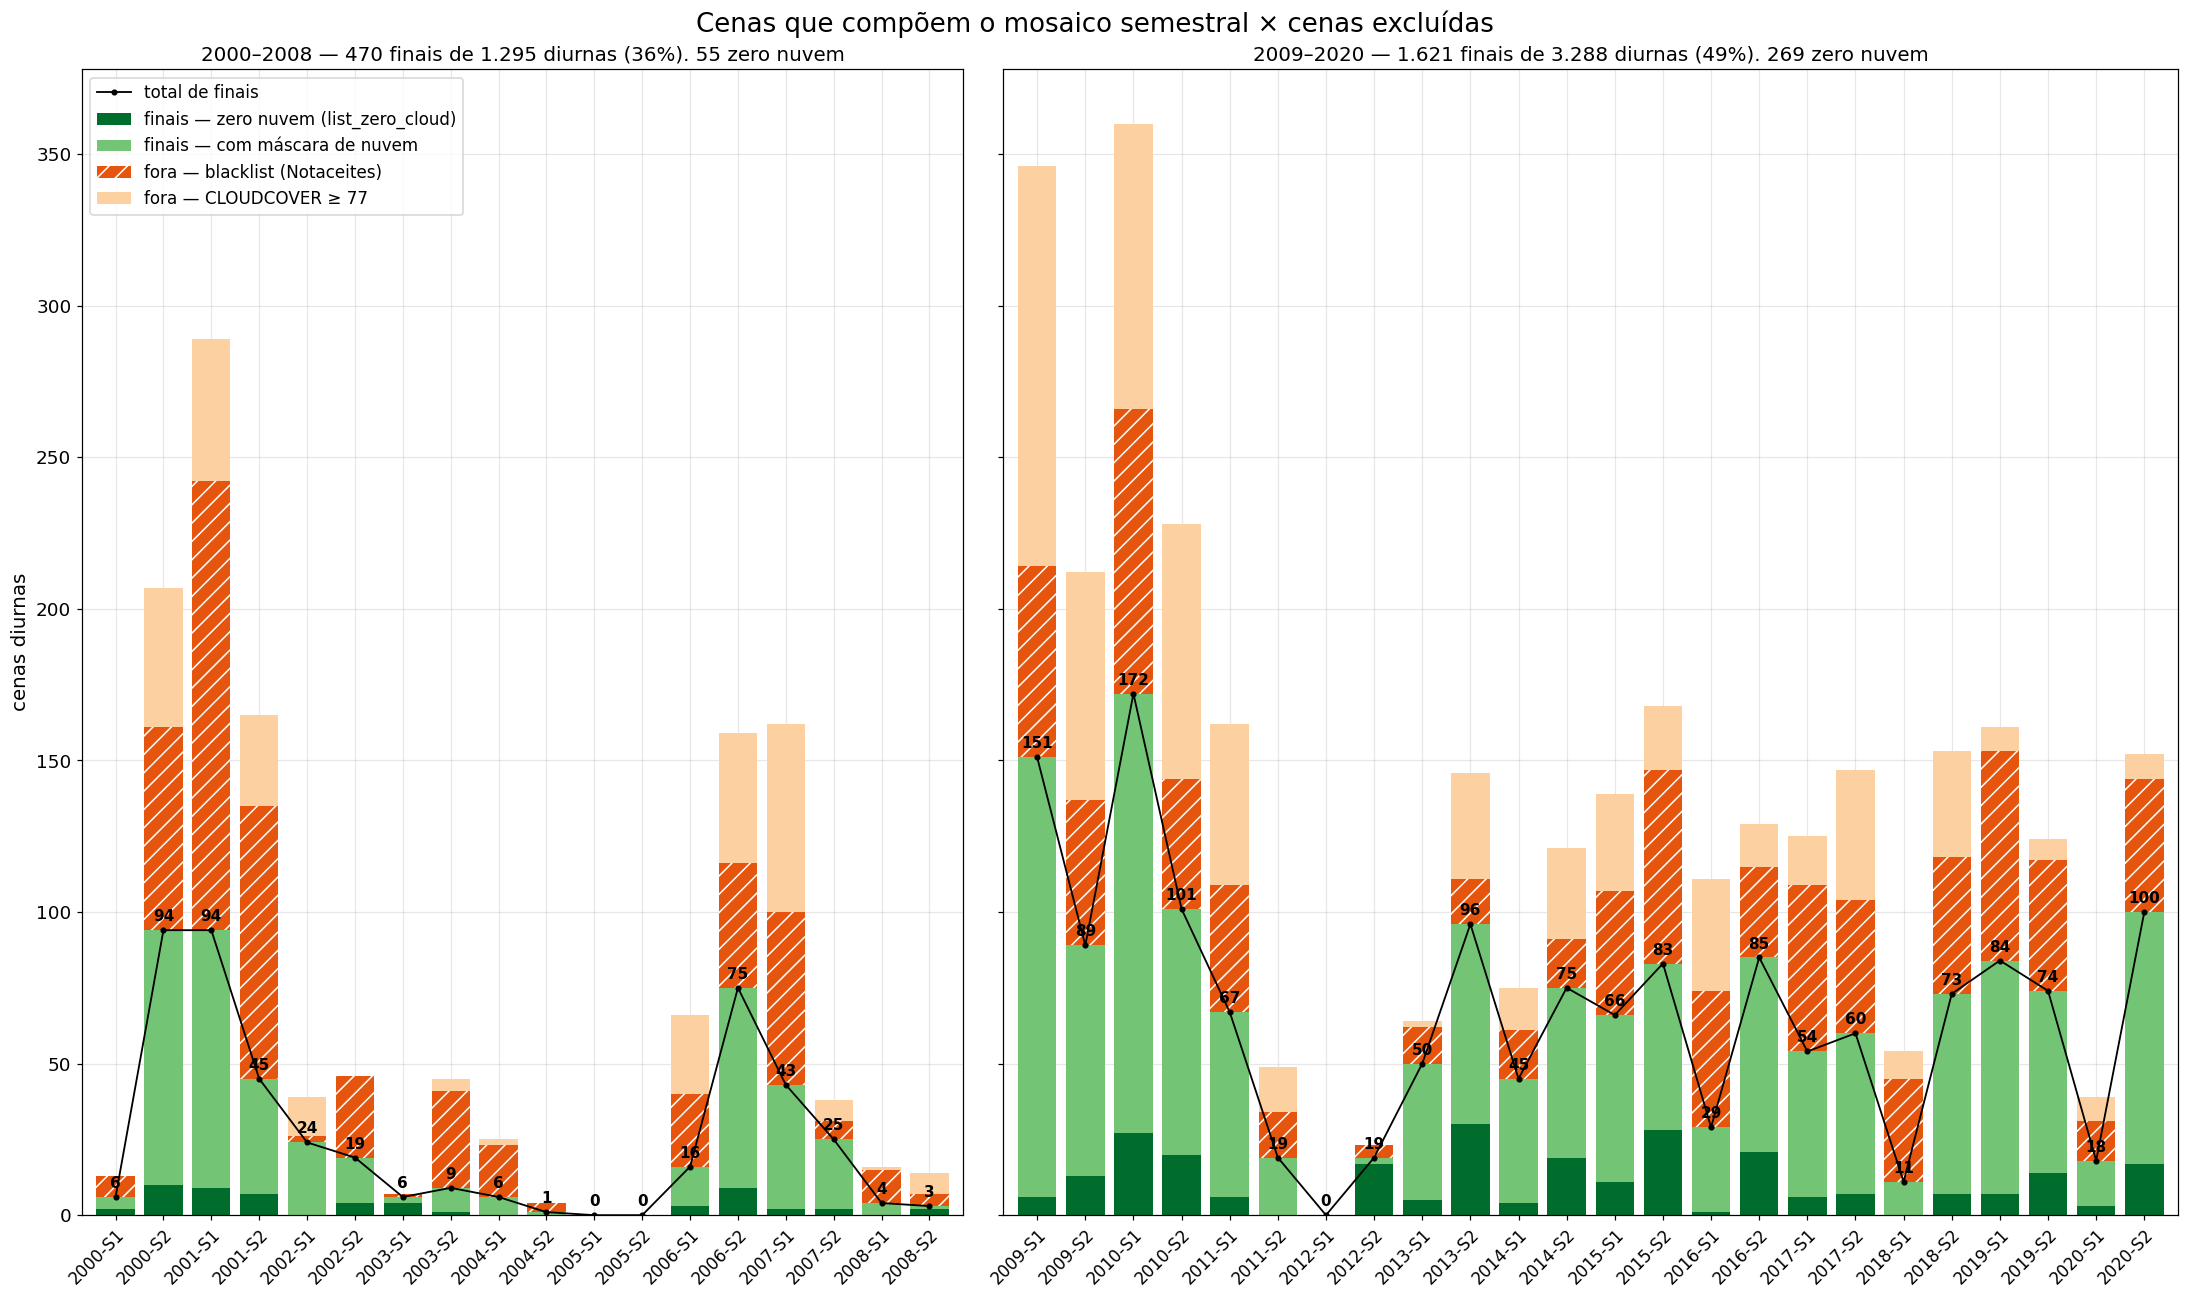

In [11]:
# [6]
fig, axs = plt.subplots(1, 2, figsize=(20, 12), sharey=True,
                        gridspec_kw={'width_ratios': [18, 24]})
for ax, (nome, (a0, a1)) in zip(axs, PERIODOS.items()):
    d = df[(df.ano >= a0) & (df.ano <= a1)].reset_index(drop=True)
    x = np.arange(len(d))
    ax.bar(x, d.zero_cloud, color=COR['zero'], label='finais — zero nuvem (list_zero_cloud)')
    ax.bar(x, d.finais_mascara, bottom=d.zero_cloud, color=COR['mascara'], label='finais — com máscara de nuvem')
    ax.bar(x, d.fora_blacklist, bottom=d.finais, color=COR['blacklist'], hatch='//', edgecolor='w', lw=0,
           label='fora — blacklist (Notaceites)')
    ax.bar(x, d.fora_nuvem, bottom=d.cc_lt_max, color=COR['nuvem'], label='fora — CLOUDCOVER ≥ 77')
    ax.plot(x, d.finais, 'k-o', ms=3, lw=1.2, label='total de finais')
    for xi, v in zip(x, d.finais):
        ax.text(xi, v + 2, str(v), ha='center', va='bottom', fontsize=FS - 3, fontweight='bold')
    ax.set_xticks(x, d.rotulo, rotation=45, ha='right', rotation_mode='anchor', fontsize=FS - 2)
    ax.tick_params(axis='y', labelsize=FS - 1)
    pct = 100 * d.finais.sum() / max(d.diurnas.sum(), 1)
    ax.set_title(f'{nome} — {d.finais.sum():,} finais de {d.diurnas.sum():,} diurnas ({pct:.0f}%), '
                 f'{d.zero_cloud.sum():,} zero nuvem'.replace(',', '.'), fontsize=FS)
    ax.set_xlim(-0.7, len(d) - 0.3)
axs[0].set_ylabel('cenas diurnas', fontsize=FS)
axs[0].legend(loc='upper left', fontsize=FS - 2)
fig.suptitle('Cenas que compõem o mosaico semestral × cenas excluídas', fontsize=FS + 4)
fig.tight_layout()
salvar(fig, '6', 'finais_blacklist_zero_cloud')

`[7]`

## Gráfico 3 — resumo por período

Totais dos dois períodos lado a lado: quanto do disponível vira imagem final
e quanto disso é zero nuvem. Percentuais em relação às cenas diurnas.

figura → c8_resumo_periodos.png


,disponíveis (diurnas),fora por nuvem (CC ≥ 77),fora pela blacklist,finais (mosaico),finais zero nuvem,semestres,finais por semestre
periodo,,,,,,,
2000–2008,1295,288,537,470,55,18,26.1
2009–2020,3288,772,895,1621,269,24,67.5


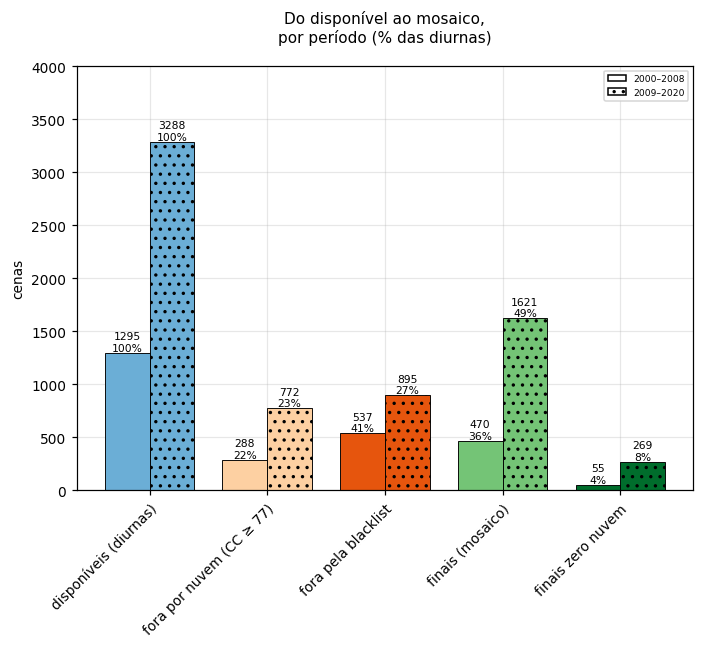

In [27]:
# [8]
cols = {'diurnas': 'disponíveis (diurnas)', 'fora_nuvem': 'fora por nuvem (CC ≥ 77)',
        'fora_blacklist': 'fora pela blacklist', 'finais': 'finais (mosaico)', 'zero_cloud': 'finais zero nuvem'}
res = df.groupby('periodo')[list(cols)].sum().rename(columns=cols)
res['semestres'] = df.groupby('periodo').size()
res['finais por semestre'] = (res['finais (mosaico)'] / res['semestres']).round(1)

fig, ax = plt.subplots(figsize=(6.5, 6))
x = np.arange(len(cols)); w = 0.38
cores_bar = ['#6baed6', COR['nuvem'], COR['blacklist'], COR['mascara'], COR['zero']]
for k, per in enumerate(res.index):
    v = res.loc[per, list(cols.values())].values.astype(float)
    barras = ax.bar(x + (k - 0.5) * w, v, w, color=cores_bar, edgecolor='k', lw=0.6,
                    hatch=None if k == 0 else '..', label=per)
    for b_, val in zip(barras, v):
        ax.text(b_.get_x() + b_.get_width() / 2, val, f'{int(val)}\n{100 * val / v[0]:.0f}%',
                ha='center', va='bottom', fontsize=FS - 6)
ax.set_xticks(x, list(cols.values()), rotation=45, ha='right', rotation_mode='anchor', fontsize=FS - 4)
ax.tick_params(axis='y', labelsize=FS - 4)
ax.set_ylabel('cenas', fontsize=FS - 4)
ax.set_ylim(0, 4000)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(fc='w', ec='k', label='2000–2008'), Patch(fc='w', ec='k', hatch='..', label='2009–2020')], fontsize=FS - 7)
ax.set_title('Do disponível ao mosaico,\npor período (% das diurnas)', fontsize=FS - 3, pad=16)
fig.tight_layout()
salvar(fig, '8', 'resumo_periodos')
res

`[9]`

## Gráfico 4 — nuvem média por semestre (apoio)

CLOUDCOVER médio e mediano das cenas diurnas, para ver se semestres com
poucas finais são de muita nuvem (S1, chuvoso) ou de poucas cenas.

figura → c10_nuvem_semestre.png


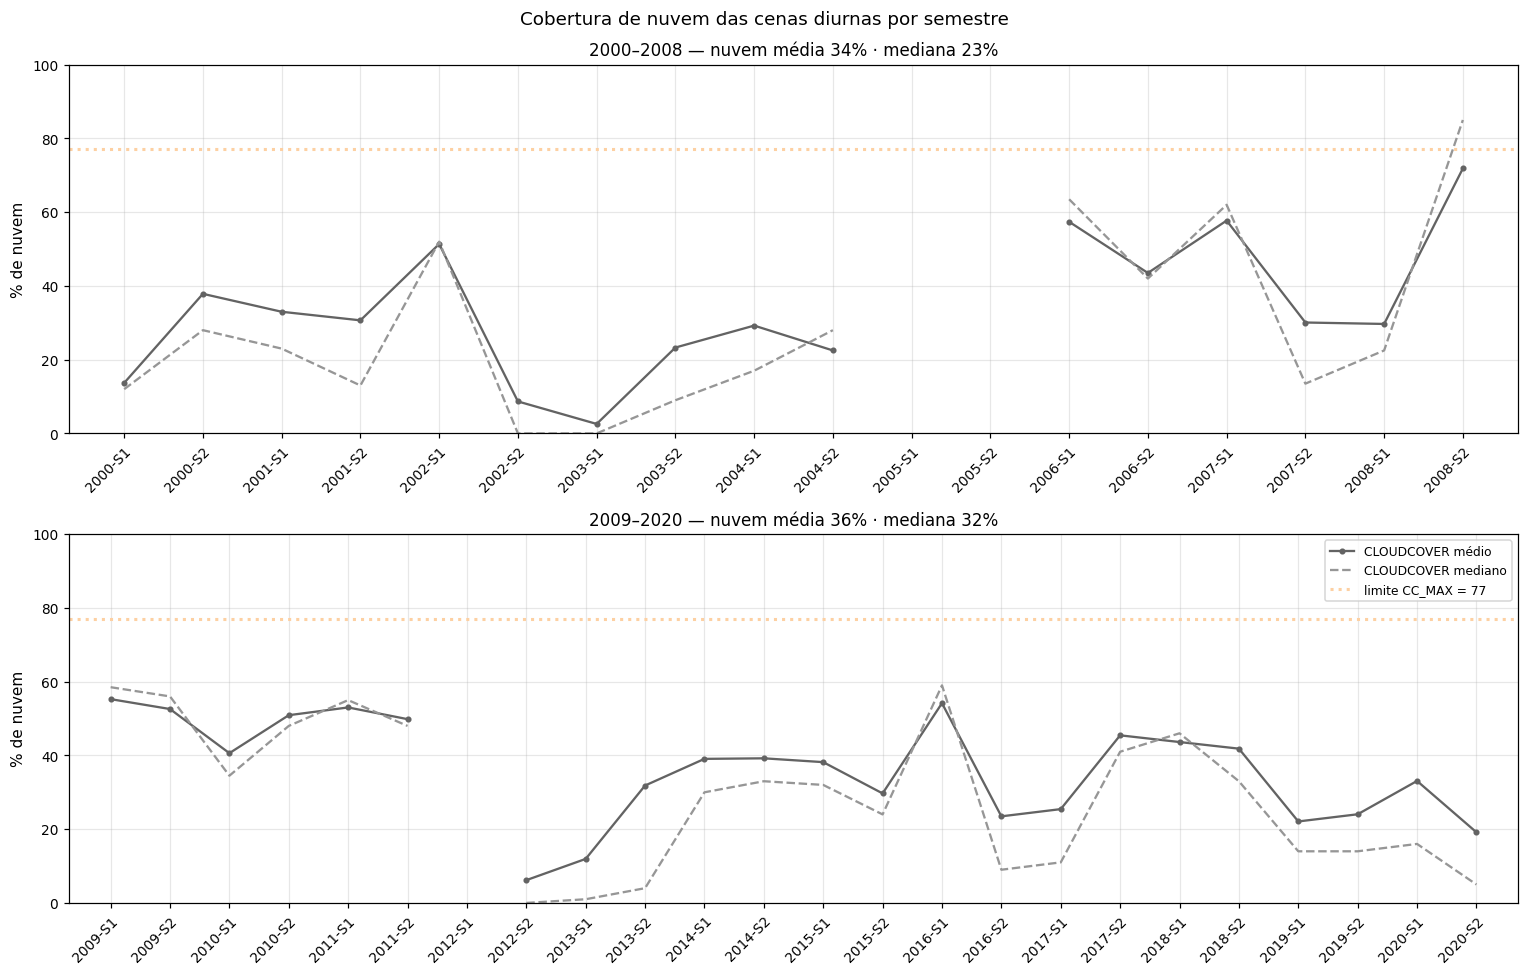

In [30]:
# [10]
# um painel por período, um acima do outro; mesmo eixo Y (0–100 %) para comparar
fig, axs = plt.subplots(2, 1, figsize=(14, 9))
for ax, (nome, (a0, a1)) in zip(axs, PERIODOS.items()):
    d = df[(df.ano >= a0) & (df.ano <= a1)].reset_index(drop=True)
    x = np.arange(len(d))
    ax.plot(x, d.cc_media, '-o', ms=3, c='#636363', label='CLOUDCOVER médio')
    ax.plot(x, d.cc_mediana, '--', c='#969696', label='CLOUDCOVER mediano')
    ax.axhline(77, c=COR['nuvem'], ls=':', lw=2, label='limite CC_MAX = 77')
    ax.set_xticks(x, d.rotulo, rotation=45, ha='right', rotation_mode='anchor', fontsize=FS - 4)
    ax.tick_params(axis='y', labelsize=FS - 4)
    ax.set_xlim(-0.7, len(d) - 0.3)
    ax.set_ylim(0, 100)
    ax.set_ylabel('% de nuvem', fontsize=FS - 3)
    ax.set_title(f'{nome} — nuvem média {d.cc_media.mean():.0f}% · mediana {d.cc_mediana.median():.0f}%',
                 fontsize=FS - 2)
axs[1].legend(loc='upper right', fontsize=FS - 5)
fig.suptitle('Cobertura de nuvem das cenas diurnas por semestre', fontsize=FS - 1)
fig.tight_layout()
salvar(fig, '10', 'nuvem_semestre')